# Week 6 · From pandas to GeoPandas

**CMT124** · Thursday 12 November 2026

Today you meet **pandas**, Python's library for tables, and then give those tables a location. We start with a real table of CO₂ emissions, turn coordinates into points and countries into polygons, watch a messy government dataset being cleaned, and finish with the grids of pixels behind every satellite image.

By the end of today you can load, inspect, filter, sort and group a table with pandas; build a **GeoDataFrame**, choose a sensible **CRS**, measure, buffer and **join by location**; and explain what a **raster** is (pixels, bands, resolution, extent, CRS, NDVI).

Today has three teaching parts and a guided lab: **Hour 1** pandas essentials on CO₂ data · **Hour 2** from DataFrame to GeoDataFrame · **Hour 3** real data in, raster foundations out · **Guided lab** renewable energy projects by local authority.

### Setup

Run this cell first. It loads the libraries and a helper, `get_data()`, that finds the course datasets. pandas, GeoPandas and Matplotlib are already installed in Colab.

In [ ]:
# --- Setup: run this cell first -------------------------------------------------
# Course datasets live in the course repository under 2026-27/datasets/.
# get_data() uses a local copy if the notebook runs inside a copy of the repository;
# otherwise (e.g. in Google Colab) it downloads the file once and reuses it.
import os
import urllib.request

COURSE_REPO = "OWNER/REPO"
BASE_URL = f"https://raw.githubusercontent.com/{COURSE_REPO}/main/2026-27/"


def course_file(relpath):
    """Return a local path to a course file such as 'datasets/owid_co2_cleaned.csv'."""
    for root in ("../../..", "."):                     # 1) running inside a copy of the repository
        path = os.path.join(root, relpath)
        if os.path.exists(path):
            return path
    path = os.path.join("course_files", relpath)       # 2) Colab: download once
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        urllib.request.urlretrieve(BASE_URL + relpath, path)
    return path


def get_data(name):
    """Return a local path to a course dataset, e.g. get_data('owid_co2_cleaned.csv')."""
    return course_file("datasets/" + name)

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

## Hour 1 · pandas essentials on real CO₂ data

### Why a new library?

In Week 5 a numpy array held **one type** of value and you reached it by **position**. Real data rarely looks like that. A table of emissions has a text column (the country), whole numbers (the year) and decimals (the tonnes of CO₂), and you want to ask for things by **name**: "the `co2` column", "the row for 1990".

**pandas** gives you exactly that: the **DataFrame**, a table with named columns, one type per column, and labels for the rows.

```python
import pandas as pd
```

Our data today is the **Our World in Data CO₂ table** (a cleaned copy): one row per country, or group of countries, per year, from 1750 to 2023. Emissions (`co2`) are in million tonnes.

### Anatomy of a DataFrame

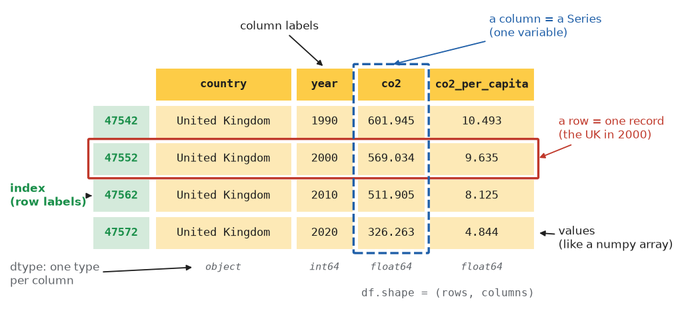

* Each **column** is one variable and has one **dtype** (`object` is pandas' word for text). A single column on its own is a **Series**.
* Each **row** is one record: here, one country in one year.
* The **index** holds the row labels. They are labels, not positions: these four rows keep the numbers they had in the full table.

**Before we run this:** the table covers about 250 countries and regions over 274 years. Will it have more or fewer than 250 × 274 ≈ 68,000 rows?

In [ ]:
df = pd.read_csv(get_data("owid_co2_cleaned.csv"))
df.shape

**50,191 rows** and **11 columns**: fewer than 68,000, because many countries only have records for recent years. `shape` is a tuple `(rows, columns)`, just like a numpy array's.

The first things to run on any new table:

In [ ]:
# ✍️ Type along: a first look at the table (head, dtypes, info, describe)

<details><summary>Code from class</summary>

```python
df.head()          # the first five rows (tail() gives the last ones)
df.dtypes          # one type per column
df.info()          # columns, non-missing counts and dtypes in one view
df.describe()      # count, mean, min, max ... of every numeric column
```
Run them one per cell: a notebook only displays the **last** expression of a cell.

</details>

**Quick check:** `country` has dtype `object`, `year` is `int64` and `co2` is `float64`. Why can't the whole table simply be one numpy array?

<details><summary>Answer</summary>

A numpy array holds **one** type. This table mixes text, whole numbers and decimals, so pandas stores each column separately with its own dtype.

</details>

### Missing values are not zeros

`info()` showed that some columns have fewer non-missing values than others. pandas marks a missing value as **`NaN`** ("not a number").

**Predict:** `co2` is missing in about 21,000 rows. Does a missing `co2` mean the country emitted **nothing** that year, or that there is **no record**?

In [ ]:
df.isna().sum()

In [ ]:
df[["country", "year", "co2"]].head(3)

Afghanistan in 1750 has no `co2` value. Nobody measured it: that is **no record**, not zero emissions. The table also contains real zeros, and they mean something different:

In [ ]:
print("rows with co2 recorded:", df.dropna(subset=["co2"]).shape[0])
print("rows with co2 exactly 0:", (df["co2"] == 0).sum())

* `dropna(subset=["co2"])` **removes** the rows where `co2` is missing.
* `fillna(0)` would **replace** `NaN` by 0, and so claim zero emissions in 1750. Only fill when you know what a missing value means.

### Filtering rows with a Boolean mask

Week 5's Boolean masks work on columns: a comparison gives one `True`/`False` per row, and `df[mask]` keeps the `True` rows.

In [ ]:
# ✍️ Type along: only the United Kingdom, only years with a CO₂ value, three columns

<details><summary>Code from class</summary>

```python
uk = df[df["country"] == "United Kingdom"]     # rows: a Boolean mask
uk = uk.dropna(subset=["co2"])                 # rows: drop the missing co2
uk = uk[["year", "co2", "co2_per_capita"]]     # columns: a list of names
print(uk.shape)
uk.head()
```

</details>

Combine conditions with `&` (and) or `|` (or), with brackets around each one, as in Week 5:

In [ ]:
big_2023 = df[(df["year"] == 2023) & (df["co2"] > 5000)]
big_2023[["country", "co2"]]

Only one of these is a single country. The table also holds **groups** of countries (the world, continents, income groups): something to remember before ranking "countries".

### Selecting with `loc` and `iloc`

| | selects by | a slice `a:b` |
|---|---|---|
| `df.loc[rows, columns]` | **labels** (index labels, column names) | **includes** `b` |
| `df.iloc[rows, columns]` | **positions** (0, 1, 2, …) | **excludes** `b`, like a list |

`set_index("year")` makes the year the row label, so we can ask for years directly.

**Quick check:** to get "the row for 1990" from the UK table, would you use `loc` or `iloc`?

<details><summary>Answer</summary>

`loc`, with the year as the index: `uk.loc[1990]`. With `iloc` you would need to know that 1990 is at position 240 (counting from 1750), and that position changes as soon as you filter the table.

</details>

In [ ]:
uk = df[df["country"] == "United Kingdom"].set_index("year")
print(uk.loc[1990, "co2"])
print(uk.loc[2018:2020, ["co2", "co2_per_capita"]])
print(uk.iloc[-3:, 3:5])

`loc[2018:2020]` **includes** 2020; `iloc[-3:, 3:5]` takes the last three rows by position and the columns at positions 3 and 4 (`co2`, `co2_per_capita`).

### Sorting

**Predict:** sorting the 2023 rows by `co2`, largest first, which "country" comes out on top?

In [ ]:
rows_2023 = df[df["year"] == 2023]
rows_2023.sort_values("co2", ascending=False)[["country", "co2"]].head(6)

`World`, then groups such as `Non-OECD (GCP)` and `Asia`. The first real country, China, is only seventh. A sorted table answers the question you **asked**, not the one you **meant**: check what the rows are.

### Group by: split → apply → combine

"Mean emissions per decade" or "the highest value per country" are **group** questions. pandas answers them in three steps:

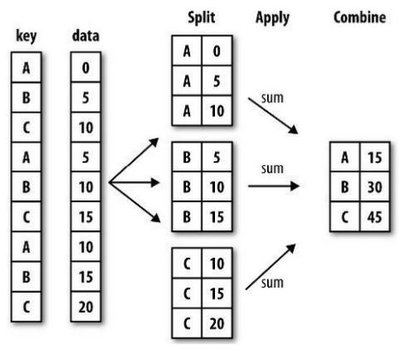

*Figure: W. McKinney, Python for Data Analysis (O'Reilly).*

In [ ]:
# ✍️ Type along: mean UK emissions per decade
uk = df[df["country"] == "United Kingdom"].dropna(subset=["co2"]).copy()

<details><summary>Code from class</summary>

```python
uk = df[df["country"] == "United Kingdom"].dropna(subset=["co2"]).copy()
uk["decade"] = (uk["year"] // 10) * 10          # a new column: 1994 -> 1990
uk.groupby("decade")["co2"].mean().tail(6)      # split by decade, apply mean, combine
```
`.copy()` makes `uk` an independent table, so adding a column to it doesn't touch `df`.

</details>

The same pattern on the whole table: the highest yearly emissions ever recorded for each "country". Select the column **before** the function: in pandas 2, `df.groupby("country").max()` would also try to work on every other column.

In [ ]:
peaks = df.groupby("country")["co2"].max()
peaks.sort_values(ascending=False).head(5)

### Text columns: `.str`

String methods from Week 1 work on a whole text column through `.str`. The groups of countries from the Global Carbon Project all end in `(GCP)`:

In [ ]:
names = pd.Series(df["country"].unique())
names[names.str.contains("GCP")].tolist()

In [ ]:
print(names[names.str.startswith("United")].tolist())
print(names.str.upper().head(3).tolist())

`names.str.contains("GCP")` is a Boolean mask, so it filters like any other.

**Your turn:** in which year did **Germany's** CO₂ emissions peak, and how high were they? Then try a country of your choice.

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
ger = df[df["country"] == "Germany"].dropna(subset=["co2"])
ger.sort_values("co2", ascending=False)[["year", "co2"]].head(1)
```
**1979**, about 1,118 million tonnes. (The UK peaked in 1971, the United States in 2005; China's highest value is its latest year, 2023.)

</details>

### Takeaways: pandas essentials

* A **DataFrame** is a table: named columns with one dtype each, and an **index** of row labels. One column is a **Series**.
* First look: `head()`, `shape`, `dtypes`, `info()`, `describe()`, `isna().sum()`.
* `NaN` means **no record**, not zero: decide between `dropna` and `fillna` on purpose.
* Rows: Boolean masks; labels: `loc` (stop included); positions: `iloc` (stop excluded); order: `sort_values`.
* `groupby(key)[column].mean()`: split → apply → combine. `.str` brings string methods to a whole column.

## Hour 2 · From DataFrame to GeoDataFrame

### A table with coordinates is not yet a map

A table can hold a longitude and a latitude, but pandas sees two ordinary numbers. It can't measure a distance, test "is this point inside Wales?" or draw a map. For that we need two more things:

* a **geometry** for each row: a point, a line or a polygon;
* a **coordinate reference system (CRS)** that says what the numbers mean.

Spatial data comes in two main forms:

| Vector | Raster |
|---|---|
| 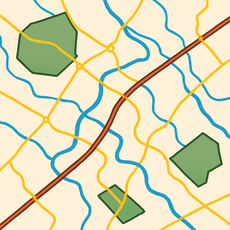 | 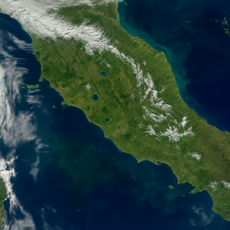 |
| **features** with exact shapes: points, lines, polygons | a **grid of pixels**, each holding a value |

This hour is about **vector** data; rasters close the day in Hour 3.

### Three geometry types

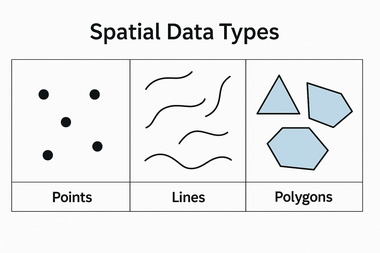

**Points** (a city, a sensor, a wind farm), **lines** (a river, a road) and **polygons** (a country, a national park, a council area). GeoPandas stores them in a column called `geometry`.

### The GeoDataFrame

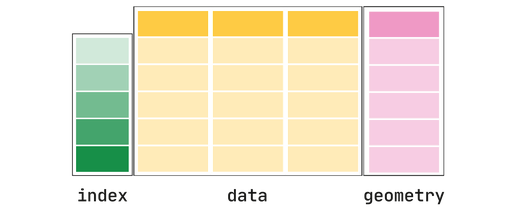

A **GeoDataFrame** is the DataFrame from Hour 1 plus a `geometry` column and a CRS. Everything from Hour 1 still works on it: filters, `loc`, `sort_values`, `groupby`. What's new is that it can measure, test locations and draw itself.

### Points from longitude and latitude

Four cities, in an ordinary DataFrame:

In [ ]:
df_cities = pd.DataFrame({
    "city": ["Cardiff", "London", "Edinburgh", "Belfast"],
    "lon": [-3.1791, -0.1276, -3.1883, -5.9301],
    "lat": [51.4816, 51.5072, 55.9533, 54.5973],
})

In [ ]:
# ✍️ Type along: turn the table into a GeoDataFrame of points

<details><summary>Code from class</summary>

```python
cities = gpd.GeoDataFrame(
    df_cities,
    geometry=gpd.points_from_xy(df_cities["lon"], df_cities["lat"]),   # x = longitude, y = latitude
    crs="EPSG:4326",
)
cities
```
`points_from_xy` takes **x first**: longitude, then latitude. Swapping them puts Cardiff in the Indian Ocean.

</details>

### Coordinate reference systems

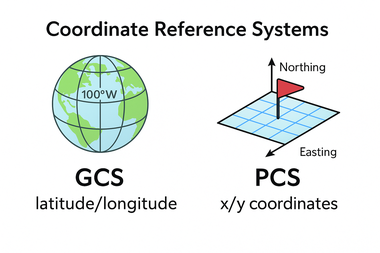

| CRS | Type | Units | Used for |
|---|---|---|---|
| `EPSG:4326` (WGS84) | geographic | **degrees** | GPS, web maps, most CSVs with lat/lon |
| `EPSG:27700` (British National Grid) | projected | **metres** | UK data, measuring in Great Britain |
| `EPSG:3857` (Web Mercator) | projected | metres (distorted) | web map tiles |

**Predict:** our points are in `EPSG:4326`. What will `distance` give for Cardiff to London, and in which unit?

In [ ]:
cities = gpd.GeoDataFrame(df_cities, geometry=gpd.points_from_xy(df_cities["lon"], df_cities["lat"]),
                          crs="EPSG:4326")
cardiff = cities.loc[0, "geometry"]
cities.distance(cardiff)

About **3.05 for London**: a distance in **degrees**, and GeoPandas warns us. A degree is not a fixed length: a degree of longitude is about 111 km at the equator but only about 69 km at Cardiff's latitude. To measure, **reproject** into a CRS that uses metres:

In [ ]:
# ✍️ Type along: reproject to the British National Grid and measure again

<details><summary>Code from class</summary>

```python
cities_m = cities.to_crs(epsg=27700)           # same places, new coordinates (metres)
cities_m                                       # the POINT numbers have changed
(cities_m.distance(cities_m.loc[0, "geometry"]) / 1000).round(1)   # km
```

</details>

Cardiff to London is about **212 km** in a straight line, Edinburgh about **498 km**. `to_crs` changes the coordinates, not the places.

### Buffers and `within`

A **buffer** is the area within a given distance of a geometry. Around a point, it's a circle.

**Predict:** which of the four cities lie within **250 km** of Cardiff?

In [ ]:
cities_m = cities.to_crs(epsg=27700)
zone = cities_m.loc[0, "geometry"].buffer(250_000)     # 250 km, in metres
cities_m[cities_m.within(zone)]["city"].tolist()

Cardiff and London. `within` asks "is each point **completely inside** the zone?". Its partner `intersects` asks "does it **touch or overlap** the zone?", which is the useful test for large polygons such as countries.

**Discuss:** why did we buffer in `EPSG:27700` and not in `EPSG:4326`? What shape would `buffer(1)` (one degree) have on the ground at Cardiff?

<details><summary>Answer</summary>

In `EPSG:4326` the unit is the degree, and a degree of longitude is shorter than a degree of latitude away from the equator. `buffer(1)` would be a "circle" about 111 km north–south but only about 69 km east–west: an ellipse on the ground, and its size changes with latitude. In metres, 250 km means 250 km in every direction.

</details>

### Polygons: the countries of the world

Natural Earth publishes free country boundaries. One file gives one polygon per country:

In [ ]:
world = gpd.read_file(get_data("ne_110m_admin_0_countries.zip"))
world = world[["NAME", "CONTINENT", "POP_EST", "GDP_MD", "geometry"]]
print(world.shape, world.crs)
world.plot(figsize=(8, 4));

**Your turn:** which countries **intersect** a **500 km** buffer around Cardiff? Buffer in metres, so reproject `world` as well.

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
world_m = world.to_crs(epsg=27700)
zone500 = cities_m.loc[0, "geometry"].buffer(500_000)
world_m[world_m.intersects(zone500)]["NAME"].tolist()
```
France, Belgium, the Netherlands, Ireland and the United Kingdom. Both layers must be in the **same** CRS before you compare them.

</details>

### Spatial join: which polygon is each point in?

A normal join matches rows by a shared **value**. A **spatial join** (`gpd.sjoin`) matches rows by **location**: each point gets the columns of the polygon it lies `within`. Here are twenty very large cities (approximate centre coordinates):

In [ ]:
big = pd.DataFrame({
    "city": ["Tokyo", "Delhi", "Shanghai", "São Paulo", "Mexico City", "Cairo", "Mumbai",
             "Beijing", "Dhaka", "Osaka", "New York", "Karachi", "Buenos Aires", "Chongqing",
             "Istanbul", "Kolkata", "Manila", "Lagos", "Rio de Janeiro", "Tianjin"],
    "lon": [139.69, 77.21, 121.47, -46.63, -99.13, 31.24, 72.88, 116.41, 90.41, 135.50,
            -74.01, 67.01, -58.38, 106.55, 28.98, 88.36, 120.98, 3.38, -43.17, 117.36],
    "lat": [35.69, 28.61, 31.23, -23.55, 19.43, 30.04, 19.08, 39.90, 23.81, 34.69,
            40.71, 24.86, -34.60, 29.56, 41.01, 22.57, 14.60, 6.52, -22.91, 39.34],
})
big = gpd.GeoDataFrame(big, geometry=gpd.points_from_xy(big["lon"], big["lat"]), crs="EPSG:4326")

**Predict:** after the join, will every city have a country?

In [ ]:
joined = gpd.sjoin(big, world, how="left", predicate="within")
joined[["city", "NAME", "CONTINENT"]]

Nineteen matches, and **Istanbul** has `NaN`. This world map is drawn at a coarse scale (1:110 million), and the point for Istanbul falls in the water of the Bosphorus. `how="left"` keeps every point, matched or not, so we can see what didn't match. You'll meet the same effect in the lab.

### Counting per area, then `merge` the counts back

Count how many cities each country got, with `value_counts`. `reset_index()` turns the result into a small table with two columns, `NAME` and `count`:

In [ ]:
counts = joined["NAME"].value_counts().reset_index()
counts.head()

To map these numbers we need them **on the country polygons**. `merge` joins two tables on a **shared column**, like a database join:

```python
world.merge(counts, on="NAME", how="left")    # every row of world, plus a count where NAME matches
```

**Before we run this:** `world` has 177 rows and `counts` has 12. How many rows will the merged table have, and what will the count be for France?

In [ ]:
world_counts = world.merge(counts, on="NAME", how="left")
print(world_counts.shape)
world_counts[world_counts["NAME"].isin(["China", "India", "France"])][["NAME", "count"]]

**177 rows**: `how="left"` keeps every country. France has no matching row in `counts`, so its count is `NaN`. Here a missing count really does mean **zero cities**, so filling with 0 is correct (compare the CO₂ table, where it wasn't):

In [ ]:
world_counts["count"] = world_counts["count"].fillna(0)
world_counts.sort_values("count", ascending=False)[["NAME", "count"]].head(3)

Two different joins: **`sjoin`** matches by **location** (point in polygon), **`merge`** matches by a **shared value** (the country name).

### A map coloured by a column

`.plot(column=...)` colours each polygon by the values of one column: a **choropleth** map.

In [ ]:
ax = world_counts.plot(column="count", cmap="YlOrRd", legend=True, figsize=(10, 5),
                       edgecolor="grey", linewidth=0.3, legend_kwds={"shrink": 0.6, "label": "cities"})
big.plot(ax=ax, color="black", markersize=6)            # a second layer on the same axes
ax.set_title("How many of the 20 cities each country has")
ax.set_axis_off()

`ax=ax` draws the cities **on top of** the map we just made: draw the polygons first, keep the `ax` they return, then add more layers to it.

China (4) and India (3) stand out. A count is easy to compute but depends on how big an area is and on how you chose the points: keep that in mind for the lab.

*Country boundaries: Made with Natural Earth (public domain).*

### Takeaways: GeoDataFrames

* GeoDataFrame = DataFrame + `geometry` column + **CRS**. Points come from `gpd.points_from_xy(lon, lat)`.
* `EPSG:4326` is in **degrees**: reproject with `to_crs(epsg=27700)` before measuring or buffering in the UK.
* `buffer`, `within` and `intersects` answer "near" and "inside" questions; layers must share a CRS.
* `gpd.sjoin` joins by **location**; `value_counts` counts per area; `merge` attaches the counts back to the polygons by a shared column.
* `.plot(column=...)` draws a choropleth map.

## Hour 3 · Real data in, raster foundations out

### The UK's renewable energy projects

The **Renewable Energy Planning Database (REPD)** lists about 13,000 UK renewable electricity projects that have gone through planning: wind and solar farms, batteries, hydro and more. In the lab you'll count them per local authority; next week you'll map them interactively.

Government data rarely arrives clean. **Watch** how the raw file becomes `repd_cleaned.csv`, and predict each problem before it appears. You won't repeat these steps: the lab starts from the cleaned file.

*REPD, Q2 July 2025, Department for Energy Security and Net Zero. Contains public sector information licensed under the Open Government Licence v3.0.*

**Predict:** we read the CO₂ file with a plain `pd.read_csv`. What could go wrong with a CSV file saved by Excel on Windows?

In [ ]:
# ⚠️ This cell raises an error on purpose
repd = pd.read_csv(get_data("repd_raw_q2_jul_2025.csv"))

A `UnicodeDecodeError`: pandas assumed **UTF-8**, but the file was saved in the Windows encoding **Windows-1252** (`cp1252`). Byte `0xa0` (a non-breaking space) is valid there but not in UTF-8. Tell pandas the encoding:

In [ ]:
repd = pd.read_csv(get_data("repd_raw_q2_jul_2025.csv"), encoding="cp1252", low_memory=False)
repd.shape

53 columns. We keep the nine we need and give them short names. `X-coordinate` and `Y-coordinate` are **British National Grid** coordinates in metres (`EPSG:27700`).

**Predict:** `x`, `y` and `capacity_mw` hold numbers. Which dtype will pandas give them?

In [ ]:
cols = {"Ref ID": "ref_id", "Site Name": "project_name", "Technology Type": "technology",
        "Development Status (short)": "status", "Installed Capacity (MWelec)": "capacity_mw",
        "Country": "country", "Region": "region", "X-coordinate": "x", "Y-coordinate": "y"}
df_repd = repd[list(cols)].rename(columns=cols)
df_repd.dtypes

`object`: **text**. One value that isn't a clean number is enough to make pandas read a whole column as text. Here is one culprit, found with `.str` from Hour 1:

In [ ]:
odd = df_repd["x"].str.endswith("\xa0", na=False)
df_repd[odd][["project_name", "x", "y"]].head(3)

`'468935\xa0'` ends in an invisible **non-breaking space**. The fix: strip spaces, then convert with `pd.to_numeric(..., errors="coerce")`, which turns anything that is still not a number (a blank capacity, for example) into `NaN`.

In [ ]:
for col in ["capacity_mw", "x", "y"]:
    text = df_repd[col].astype("string").str.replace("\xa0", " ").str.strip()
    df_repd[col] = pd.to_numeric(text, errors="coerce")
df_repd[["capacity_mw", "x", "y"]].isna().sum()

24 projects have no coordinates, so they can't be mapped and we drop them. (A missing capacity is fine: the project still has a location.)

In [ ]:
df_repd = df_repd.dropna(subset=["x", "y"]).copy()
len(df_repd)

**Predict:** British National Grid values are eastings and northings in metres, from 0 up to about 700,000 (east) and 1,300,000 (north). What does it mean if a project has an `x` **below 1,000**?

In [ ]:
in_degrees = df_repd["x"].abs() < 1000
df_repd[in_degrees][["ref_id", "project_name", "x", "y", "country"]]

One record holds **degrees**: a latitude (54.7) typed into `x` and a longitude (−5.7) into `y`, for a project in Northern Ireland. Treated as metres, it would sit about 50 m from the grid's origin, in the sea south-west of the Isles of Scilly. We keep it, swapping the values into the right place.

Now the conversion: build points in `EPSG:27700`, reproject with `to_crs`, and read off longitude and latitude.

In [ ]:
bng = df_repd[~in_degrees]
pts = gpd.GeoSeries(gpd.points_from_xy(bng["x"], bng["y"]), crs="EPSG:27700").to_crs("EPSG:4326")
df_repd.loc[~in_degrees, "lon"] = pts.x.values
df_repd.loc[~in_degrees, "lat"] = pts.y.values
df_repd.loc[in_degrees, "lon"] = df_repd.loc[in_degrees, "y"]    # x held the latitude,
df_repd.loc[in_degrees, "lat"] = df_repd.loc[in_degrees, "x"]    # y the longitude
repd_cleaned = df_repd.drop(columns=["x", "y"]).reset_index(drop=True)

**Predict:** if everything worked, what range should the longitudes and latitudes cover?

In [ ]:
repd_cleaned[["lon", "lat"]].describe().loc[["min", "max"]].round(2)

Longitudes from about −8.1 to 2.6 and latitudes from about 50.0 to 60.7: the UK, from Northern Ireland to East Anglia and from Cornwall to Shetland. A range check like this is a cheap test that a conversion worked.

The course file `repd_cleaned.csv` holds exactly this result (with coordinates rounded to 6 decimal places): 12,953 projects with `lon` and `lat` in `EPSG:4326`. The lab and Week 7 load it directly.

In [ ]:
course_copy = pd.read_csv(get_data("repd_cleaned.csv"))
print(course_copy.shape, repd_cleaned.shape)
course_copy.head(3)

### Raster data: a grid of values

Everything so far was **vector** data. Satellite images, elevation models and temperature maps are **rasters**: the area is covered by a **grid of cells (pixels)**, and every pixel holds a **value**.

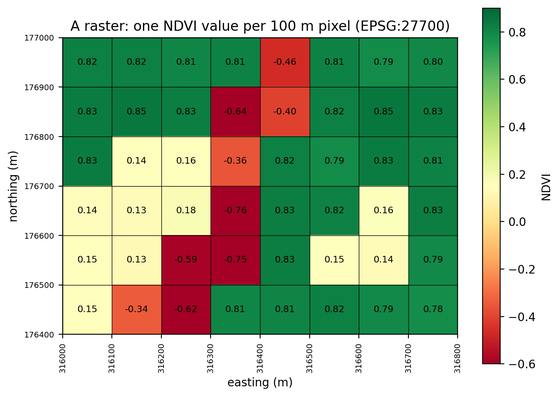

A raster is a numpy array (Week 5) that also knows **where** it is. Four things describe it:

| | Meaning | In the grid above |
|---|---|---|
| **pixel values** | one number per cell | NDVI, from −0.76 to 0.85 |
| **resolution** | the ground size of one pixel | 100 m × 100 m |
| **extent** | the area the grid covers | 800 m × 600 m |
| **CRS** | what the coordinates mean | `EPSG:27700` (metres) |

Finer resolution means more detail, but 10× finer means **100×** more pixels.

### Bands and reflectance

A satellite measures how much sunlight each pixel **reflects** in several parts of the spectrum. Each part is stored as its own grid: a **band**. A colour photo has 3 bands (red, green, blue); Sentinel-2 has 13, including **near-infrared (NIR)**.

**Reflectance** is the fraction of light reflected, from 0 to 1. Healthy leaves reflect little red light (they absorb it for photosynthesis) but a lot of NIR. (Sentinel-2 stores reflectance × 10,000 as whole numbers, so 0.3 becomes 3,000: you'll see that next week.)

Below, two bands for a small made-up area near Cardiff: vegetation, built-up land and a river. Run it; the numbers are reflectances.

In [ ]:
cover = np.array([[0, 0, 0, 0, 2, 0, 0, 0], [0, 0, 0, 2, 2, 0, 0, 0], [0, 1, 1, 2, 0, 0, 0, 0],
                  [1, 1, 1, 2, 0, 0, 1, 0], [1, 1, 2, 2, 0, 1, 1, 0], [1, 2, 2, 0, 0, 0, 0, 0]])
# 0 = vegetation, 1 = built-up, 2 = water
rng = np.random.default_rng(0)
red = np.choose(cover, [0.04, 0.15, 0.03]) + rng.normal(0, 0.005, cover.shape)
nir = np.choose(cover, [0.40, 0.20, 0.01]) + rng.normal(0, 0.005, cover.shape)
print(red.shape, red.round(2)[0], nir.round(2)[0], sep="\n")

**Band maths** combines bands pixel by pixel into a **derived** raster. The best known is the vegetation index **NDVI**:

$$\mathrm{NDVI} = \frac{\mathrm{NIR} - \mathrm{Red}}{\mathrm{NIR} + \mathrm{Red}}$$

It runs from −1 to 1: about 0.8 for dense vegetation, near 0 for buildings and bare ground.

**Predict:** over water both bands are tiny, but red is a little larger than NIR. What sign will NDVI have?

In [ ]:
# ✍️ Type along: NDVI for every pixel at once, then read single pixels

<details><summary>Code from class</summary>

```python
ndvi = (nir - red) / (nir + red)      # numpy works element-wise: one NDVI per pixel
print(ndvi.shape)
print(ndvi[0, 0].round(2), ndvi[2, 1].round(2), ndvi[2, 3].round(2))   # vegetation, built-up, water
print(ndvi.round(2))
```

</details>

**Negative** over water (about −0.4 to −0.8), close to 0.15 for built-up land, about 0.8 for vegetation. A quick look at the whole grid; `imshow` draws one coloured square per pixel:

In [ ]:
ndvi = (nir - red) / (nir + red)
plt.figure(figsize=(5, 3.5))
plt.imshow(ndvi, cmap="RdYlGn", vmin=-0.6, vmax=0.9)
plt.colorbar(label="NDVI")
plt.title("NDVI preview");

This is only a **preview**: the axes count rows and columns, not metres. Making plots properly (axes, labels, colour choices) is Week 7.

### Where is the grid? Resolution, extent and CRS

The array alone doesn't say where it is. Add the CRS, the top-left corner and the resolution, and every pixel has a place on the ground. Going the other way, the corner and the resolution tell you which pixel lies under any point:

In [ ]:
x0, y0, res = 316_000, 177_000, 100            # top-left corner (EPSG:27700, metres), pixel size
n_rows, n_cols = ndvi.shape
print("extent:", n_cols * res, "m wide,", n_rows * res, "m tall")

def pixel_at(x, y):
    """Row and column of the pixel that contains the point (x, y)."""
    return int((y0 - y) // res), int((x - x0) // res)

Rows count **down** from the top edge (`y0 - y`), columns **across** from the left edge (`x - x0`).

### Raster and vector together

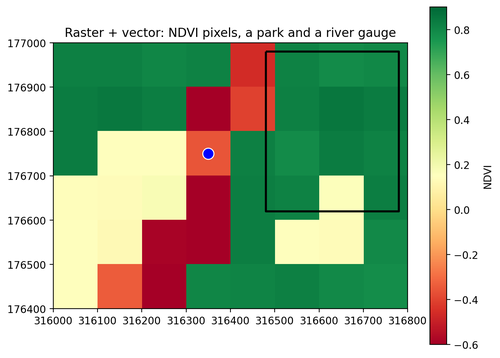

With the same CRS, vector features sit on the raster:

* a **point** takes the value of the pixel under it (the river gauge, blue dot);
* a **polygon** takes a summary of the pixels inside it (the park: 12 pixels, mean NDVI 0.76).

This is how satellite data become **rows of a table**: one row per place, columns of pixel values. It's the input to the machine-learning labs of Weeks 11 and 12.

In [ ]:
row, col = pixel_at(316_350, 176_750)     # the river gauge
print(row, col, ndvi[row, col].round(2))

**Your turn:** which pixel contains the point (316650, 176450)? What is its NDVI, and what land cover does that suggest?

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
row, col = pixel_at(316_650, 176_450)
print(row, col, ndvi[row, col].round(2))    # 5 6 0.79
```
Row 5, column 6 (the bottom row): NDVI about 0.79, so **vegetation**.

</details>

### Why Earth Engine next week?

Our raster had 48 pixels. One **Sentinel-2** satellite tile covers 100 km × 100 km at 10 m resolution: 10,980 × 10,980 ≈ **120 million pixels per band**, 13 bands, a new image every few days, and an archive going back to 2015. Downloading that and looping over it on a laptop doesn't scale.

Next week we use **Google Earth Engine**, which keeps the images and the computation on Google's servers and sends back only maps and small tables. The ideas are exactly today's: bands, reflectance, resolution, CRS, NDVI, and raster values for vector features.

### Takeaways: real data and rasters

* Real files need checking: **encoding** (`cp1252`), numbers stored as **text**, hidden spaces, **impossible coordinates**.
* `pd.to_numeric(..., errors="coerce")` converts text to numbers; a **range check** confirms a CRS conversion.
* A **raster** is a grid of pixel values (one array per **band**) plus a **CRS**, a **resolution** and an **extent**.
* Band maths makes derived rasters such as **NDVI**, positive for vegetation, negative for water.
* Points read the pixel under them; polygons summarise the pixels inside them.

## Transition to the lab

**You now know** how to load and question a table with pandas, turn coordinates into a GeoDataFrame, reproject it, join points to polygons with `sjoin`, count per area and `merge` the counts back, and draw a choropleth.

**The guided lab** (`W06b_guided_lab_student.ipynb`, one hour) puts exactly that workflow together, one step at a time, on real data: the cleaned REPD projects and the UK's **local authority districts**. Which districts have the most renewable energy projects, and is a simple count a fair way to compare them? After each step everyone compares the same checkpoint before we move on.

## Week 6 takeaways

* pandas: `read_csv`, first look, `NaN` ≠ 0, masks, `loc`/`iloc`, `sort_values`, `groupby`, `.str`.
* GeoPandas: geometry + CRS; measure and buffer in **metres**; `sjoin` by location, `merge` by value; `.plot(column=...)`.
* Cleaning real data is a sequence of small, checkable steps.
* Rasters are grids of values with a place on the Earth: pixels, bands, resolution, extent, CRS.

## Where next

**Week 7 · Visualising environmental data.** You'll plot the CO₂ table properly with Matplotlib and seaborn, put the REPD projects on **interactive Folium maps**, and open real **Sentinel-2** rasters with **Google Earth Engine**, computing NDVI on millions of pixels instead of 48.

Before next week: rerun this notebook top to bottom, and finish the guided lab if you didn't reach the last step.

## Optional: explore after class

None of this is needed for Week 7.

**The richest countries per person.** `world` has GDP (`GDP_MD`, million US dollars) and population. Make a new column and rank it; tiny territories are excluded.

In [ ]:
world["gdp_per_capita"] = world["GDP_MD"] * 1e6 / world["POP_EST"]
world[world["POP_EST"] > 5000].sort_values("gdp_per_capita", ascending=False)[["NAME", "gdp_per_capita"]].head(10)

**A basemap under your map.** The `contextily` package adds web map tiles behind a GeoPandas plot. It isn't installed in Colab, needs an internet connection, and needs the data in Web Mercator (`EPSG:3857`):

```python
%pip install -q contextily
import contextily as ctx
ax = world_counts.to_crs(epsg=3857).plot(column="count", cmap="YlOrRd", alpha=0.6, figsize=(10, 5))
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas)
```
Tiles come from an online service, so the look and availability can change.

## Credits

Data: CO₂ and greenhouse-gas emissions, Our World in Data (CC BY 4.0) · Renewable Energy Planning Database, Department for Energy Security and Net Zero (Open Government Licence v3.0) · country boundaries, Made with Natural Earth (public domain).
Figure: split–apply–combine, W. McKinney, *Python for Data Analysis* (O'Reilly).
The pandas material draws on teaching slides by Dr Luis Espinosa-Anke.